# Notebook 7 -- XGBoost face au scénario réel de panne
### Quand une bonne métrique globale cache un échec local complet

> ****Note de provenance.**** Les notebooks de recherche originaux seront présents dans le répertoire du projet, accompagnés des données et des fichiers nécessaires aux expériences. Le présent notebook fait uniquement office de **notebook d'analyse et de synthèse** : il ne remplace pas les notebooks originaux et ne constitue pas une nouvelle implémentation des expérimentations.
>
> Le code, les résultats et les sorties présentés dans ce notebook sont analysés à partir des travaux réalisés dans les notebooks originaux. Aucun résultat n'a été recalculé ni inventé : lorsqu'une information n'était pas déterminable à partir des notebooks ou des données disponibles, cela est signalé explicitement plutôt que comblé. Ce notebook n'est donc pas conçu pour être exécuté isolément de haut en bas ; il a pour objectif de **documenter, structurer, comparer et interpréter les résultats déjà obtenus**, ainsi que de mettre en évidence la progression scientifique entre les différentes approches étudiées.


## Objectif

Réévaluer les modèles XGBoost du notebook 6, non plus instant par instant sur l'ensemble du Test,
mais sur des **scénarios de panne explicitement construits** : une fenêtre continue de 10/20/30 %
du Test, une région de pics, et des points isolés aléatoires -- exactement les scénarios déjà
utilisés au notebook 5 pour le pipeline SSI+SINDy+Kalman, ce qui permet ici une comparaison
directe et loyale entre les deux familles de méthodes.

## Motivation

Le notebook 6 s'est terminé sur une mise en garde : ses bons scores (R² jusqu'à 0,80) sont
calculés sur l'ensemble du Test, où le modèle dispose à chaque instant évalué des retards
récents, réellement observés, des autres capteurs. Ce mode d'évaluation ne correspond pas
exactement au problème industriel posé au notebook 1 -- une panne prolongée du capteur cible,
potentiellement pendant un régime transitoire. Ce notebook construit six nouvelles variantes
XGBoost (instantané, contextuel, résiduel, calibré en amplitude, à correction conditionnelle, à
décomposition niveau/échelle/forme) et les évalue spécifiquement sur ces scénarios de panne, avec
des métriques supplémentaires (ratio d'amplitude, ratio d'écart-type, taux de détection de pics)
conçues pour ne pas laisser une métrique unique masquer un échec localisé.

## Hypothèse

Un modèle XGBoost, même performant en évaluation instant par instant (notebook 6), reconstruit
correctement le capteur cible sur une véritable fenêtre de panne continue -- y compris sa
variance et son amplitude, pas seulement sa tendance moyenne.

## Méthodologie

Construction de deux jeux de features : un jeu **instantané** (valeurs courantes des capteurs
disponibles) et un jeu **contextuel** (ajout de retards à 1/2/3/6/12 pas, différences d'ordre 1 et
2, statistiques glissantes sur 5/15/30 pas -- toutes décalées d'un pas pour n'utiliser aucune
information future).

In [19]:
def make_features(other_sensors, temporal=False):
    other_sensors = other_sensors.astype(float).copy()
    features = {f"current__{c}": other_sensors[c] for c in other_sensors.columns}
    if temporal:
        for c in other_sensors.columns:
            previous = other_sensors[c].shift(1)
            for lag in TEMPORAL_LAGS:
                features[f"{c}__lag_{lag}"] = other_sensors[c].shift(lag)
            features[f"{c}__delta_1"] = other_sensors[c] - previous
            features[f"{c}__delta_2"] = other_sensors[c] - 2 * previous + other_sensors[c].shift(2)
            for window in ROLLING_WINDOWS:
                rolling = previous.rolling(window, min_periods=window)
                features[f"{c}__rolling_mean_{window}"] = rolling.mean()
                features[f"{c}__rolling_std_{window}"] = rolling.std()
                features[f"{c}__rolling_min_{window}"] = rolling.min()
                features[f"{c}__rolling_max_{window}"] = rolling.max()
    return pd.DataFrame(features).replace([np.inf, -np.inf], np.nan).bfill().fillna(0.0)

def split_features(history, current, temporal):
    combined = pd.concat([history, current], ignore_index=True)
    return make_features(combined, temporal=temporal).iloc[len(history):].reset_index(drop=True)

history_size = max(max(TEMPORAL_LAGS), max(ROLLING_WINDOWS))
other_train = train_s[selected_sensors].reset_index(drop=True)
other_val = val_s[selected_sensors].reset_index(drop=True)
other_test = test_s[selected_sensors].reset_index(drop=True)

def build_split_features(temporal):
    train_x = split_features(other_train.iloc[:0], other_train, temporal)
    val_x = split_features(other_train.tail(history_size), other_val, temporal)
    test_history = pd.concat([other_train, other_val], ignore_index=True).tail(history_size)
    test_x = split_features(test_history, other_test, temporal)
    return train_x, val_x, test_x

X_instant_train, X_instant_val, X_instant_test = build_split_features(temporal=False)
X_context_train, X_context_val, X_context_test = build_split_features(temporal=True)
y_train_xgb = train_s[TARGET_SENSOR].to_numpy()
y_val_xgb = val_s[TARGET_SENSOR].to_numpy()
y_test_xgb = test_s[TARGET_SENSOR].to_numpy()
assert len(X_context_test) == len(y_test_xgb) and X_context_test.index.equals(pd.RangeIndex(len(y_test_xgb)))


Six variantes sont construites successivement : XGBoost instantané, XGBoost contextuel (hyperparamètres sélectionnés par grille sur Validation), XGBoost résiduel (apprend l'erreur résiduelle du modèle contextuel, à partir de prédictions walk-forward pour éviter toute fuite), une calibration linéaire d'amplitude, une correction conditionnelle, et une décomposition niveau/échelle/forme du résidu.

In [20]:
def select_and_fit_xgb(X_train, y_train, X_val, y_val, label):
    trials = []
    for params in XGB_GRID:
        model = XGBRegressor(**params, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0)
        model.fit(X_train, y_train)
        trials.append((np.sqrt(mean_squared_error(y_val, model.predict(X_val))), params))
    validation_rmse, chosen = min(trials, key=lambda item: item[0])
    final_model = XGBRegressor(**chosen, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0)
    final_model.fit(pd.concat([X_train, X_val], ignore_index=True), np.r_[y_train, y_val])
    print(f"{label} — RMSE validation: {validation_rmse:.5f}; paramètres: {chosen}")
    return final_model, chosen

xgb_instant, params_instant = select_and_fit_xgb(X_instant_train, y_train_xgb, X_instant_val, y_val_xgb, "XGBoost instantané")
xgb_context, params_context = select_and_fit_xgb(X_context_train, y_train_xgb, X_context_val, y_val_xgb, "XGBoost contexte")
pred_instant = xgb_instant.predict(X_instant_test)
pred_context = xgb_context.predict(X_context_test)


XGBoost instantané — RMSE validation: 0.46894; paramètres: {'n_estimators': 450, 'max_depth': 4, 'learning_rate': 0.025, 'min_child_weight': 7, 'subsample': 0.9, 'colsample_bytree': 1.0}
XGBoost contexte — RMSE validation: 0.43500; paramètres: {'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.9}


In [21]:
def walk_forward_predictions(params, X, y, folds=4):
    prediction = np.full(len(y), np.nan)
    boundaries = np.linspace(max(40, len(y) // 5), len(y), folds + 1, dtype=int)
    for start, end in zip(boundaries[:-1], boundaries[1:]):
        model = XGBRegressor(**params, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0)
        model.fit(X.iloc[:start], y[:start])
        prediction[start:end] = model.predict(X.iloc[start:end])
    return prediction

oof_context_train = walk_forward_predictions(params_context, X_context_train, y_train_xgb)
valid_oof = np.isfinite(oof_context_train)
residual_train = y_train_xgb[valid_oof] - oof_context_train[valid_oof]

# Validation résiduelle : baseline entraînée sur Train seulement, donc sans fuite.
context_train_only = XGBRegressor(**params_context, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0).fit(X_context_train, y_train_xgb)
baseline_val = context_train_only.predict(X_context_val)
residual_val = y_val_xgb - baseline_val
xgb_residual, params_residual = select_and_fit_xgb(X_context_train.iloc[valid_oof].reset_index(drop=True), residual_train, X_context_val, residual_val, "XGBoost résiduel")
pred_residual = pred_context + xgb_residual.predict(X_context_test)


XGBoost résiduel — RMSE validation: 0.69940; paramètres: {'n_estimators': 250, 'max_depth': 2, 'learning_rate': 0.04, 'min_child_weight': 3, 'subsample': 0.85, 'colsample_bytree': 0.85}


In [22]:
X_context_train_val = pd.concat([X_context_train, X_context_val], ignore_index=True)
y_train_val = np.r_[y_train_xgb, y_val_xgb]
oof_train_val = walk_forward_predictions(params_context, X_context_train_val, y_train_val)
calibration_ok = np.isfinite(oof_train_val)
amplitude_calibrator = LinearRegression().fit(oof_train_val[calibration_ok, None], y_train_val[calibration_ok])
pred_context_calibrated = amplitude_calibrator.predict(pred_context[:, None])
print(f"Calibration contextuelle: y = {amplitude_calibrator.coef_[0]:.4f} × prediction + {amplitude_calibrator.intercept_:.4f}")


Calibration contextuelle: y = 1.0859 × prediction + -0.2708


In [27]:
xgb_conditional_correction, params_conditional = select_and_fit_xgb(
    X_correction_train, residual_train_oof, X_correction_val, residual_val_oof, "Correction conditionnelle"
)
X_correction_test = with_base_prediction(X_context_test, pred_context)
pred_context_conditional = pred_context + xgb_conditional_correction.predict(X_correction_test)


Correction conditionnelle — RMSE validation: 0.70050; paramètres: {'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.9}


In [28]:
SCALE_EPS = 1e-4  # unité standardisée : protège la division, sans utiliser le Test.
scale_target_train = np.log(np.abs(residual_train_oof) + SCALE_EPS)
scale_target_val = np.log(np.abs(residual_val_oof) + SCALE_EPS)
xgb_residual_scale, params_scale = select_and_fit_xgb(
    X_correction_train, scale_target_train, X_correction_val, scale_target_val, "Échelle conditionnelle du résidu"
)

# Les cibles z de Train reposent sur une échelle prédite walk-forward, pas sur une échelle
# calculée sur la fenêtre Test. Les premières observations sans historique sont ignorées.
oof_log_scale_train = walk_forward_predictions(params_scale, X_correction_train, scale_target_train)
valid_shape = np.isfinite(oof_log_scale_train)
sigma_train_oof = np.exp(oof_log_scale_train[valid_shape]).clip(SCALE_EPS, 3.0)
shape_target_train = residual_train_oof[valid_shape] / sigma_train_oof

scale_train_only = XGBRegressor(**params_scale, objective="reg:squarederror", random_state=RANDOM_SEED, n_jobs=1, verbosity=0).fit(X_correction_train, scale_target_train)
sigma_val = np.exp(scale_train_only.predict(X_correction_val)).clip(SCALE_EPS, 3.0)
shape_target_val = residual_val_oof / sigma_val
xgb_residual_shape, params_shape = select_and_fit_xgb(
    X_correction_train.iloc[valid_shape].reset_index(drop=True), shape_target_train,
    X_correction_val, shape_target_val, "Forme normalisée du résidu"
)
sigma_test = np.exp(xgb_residual_scale.predict(X_correction_test)).clip(SCALE_EPS, 3.0)
z_test = xgb_residual_shape.predict(X_correction_test)
pred_level_scale_shape = pred_context + sigma_test * z_test


Échelle conditionnelle du résidu — RMSE validation: 2.81531; paramètres: {'n_estimators': 450, 'max_depth': 4, 'learning_rate': 0.025, 'min_child_weight': 7, 'subsample': 0.9, 'colsample_bytree': 1.0}
Forme normalisée du résidu — RMSE validation: 8.98143; paramètres: {'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.9}


In [29]:
X_context_train_val = pd.concat([X_context_train, X_context_val], ignore_index=True)
y_train_val = np.r_[y_train_xgb, y_val_xgb]
oof_train_val = walk_forward_predictions(params_context, X_context_train_val, y_train_val)
calibration_ok = np.isfinite(oof_train_val)
amplitude_calibrator = LinearRegression().fit(oof_train_val[calibration_ok, None], y_train_val[calibration_ok])
pred_context_calibrated = amplitude_calibrator.predict(pred_context[:, None])
print(f"Calibration contextuelle: y = {amplitude_calibrator.coef_[0]:.4f} × prediction + {amplitude_calibrator.intercept_:.4f}")


Calibration contextuelle: y = 1.0859 × prediction + -0.2708


Les scénarios d'évaluation sont ensuite construits explicitement (fenêtre continue centrée de
10/20/30 % du Test, région de pics avec une demi-largeur de 15 échantillons, points aléatoires
isolés à 10 %), et chaque prédiction est évaluée avec, en plus des métriques habituelles, des
métriques dédiées à l'amplitude et aux pics :

In [23]:
def inverse_target(values):
    return np.asarray(values) * scaler.scale_[target_idx] + scaler.mean_[target_idx]

def evaluate_model(y_true, y_pred, mask, method, scenario):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert len(y_true) == len(y_pred) == len(mask), "Longueurs incohérentes"
    assert mask.dtype == bool and mask.any(), "Masque d'évaluation invalide"
    true, pred = y_true[mask], y_pred[mask]
    assert np.isfinite(true).all() and np.isfinite(pred).all(), "NaN/Inf détecté"
    peak_prominence = max(np.std(true) * .75, 1e-12)
    true_peaks, _ = find_peaks(true, prominence=peak_prominence)
    pred_peaks, _ = find_peaks(pred, prominence=peak_prominence)
    tolerance = max(2, len(true) // 100); used = set(); matched = []
    for peak in true_peaks:
        candidates = [p for p in pred_peaks if abs(p - peak) <= tolerance and p not in used]
        if candidates:
            detected = min(candidates, key=lambda p: abs(p - peak)); used.add(detected); matched.append((peak, detected))
    variance_ratio = np.var(pred) / np.var(true) if np.var(true) else np.nan
    std_ratio = np.std(pred) / np.std(true) if np.std(true) else np.nan
    amplitude_ratio = np.ptp(pred) / np.ptp(true) if np.ptp(true) else np.nan
    return dict(Method=method, Scenario=scenario, N_total=len(y_true), N_missing=int(mask.sum()), MAE=mean_absolute_error(true, pred), RMSE=np.sqrt(mean_squared_error(true, pred)), Normalized_RMSE=np.sqrt(mean_squared_error(true, pred))/np.std(true) if np.std(true) else np.nan, R2=r2_score(true, pred), Correlation=pearsonr(true, pred)[0] if np.std(true) and np.std(pred) else np.nan, Variance_ratio=variance_ratio, Std_ratio=std_ratio, Amplitude_ratio=amplitude_ratio, Peak_MAE=np.mean([abs(true[a]-pred[b]) for a,b in matched]) if matched else np.nan, Peak_RMSE=np.sqrt(np.mean((true[true_peaks]-pred[true_peaks])**2)) if len(true_peaks) else np.nan, Peak_amplitude_error=np.mean([abs(true[a]-pred[b]) for a,b in matched]) if matched else np.nan, Peak_detection_rate=len(matched)/len(true_peaks) if len(true_peaks) else np.nan)

y_test_physical = inverse_target(y_test_xgb)
predictions = {"XGBoost instantané": inverse_target(pred_instant), "XGBoost contexte": inverse_target(pred_context), "XGBoost contexte calibré": inverse_target(pred_context_calibrated), "XGBoost contexte + résidu": inverse_target(pred_residual)}
rng = np.random.default_rng(RANDOM_SEED); scenarios = {"Random 10%": rng.random(len(y_test_physical)) < RANDOM_MISSING_FRACTION}
for fraction in SCENARIO_FRACTIONS:
    length = max(5, int(len(y_test_physical) * fraction)); start = (len(y_test_physical) - length) // 2
    mask = np.zeros(len(y_test_physical), dtype=bool); mask[start:start+length] = True; scenarios[f"Continuous {int(fraction*100)}%"] = mask
peaks, _ = find_peaks(y_test_physical, prominence=max(np.std(y_test_physical), 1e-12)); peak_mask = np.zeros(len(y_test_physical), dtype=bool)
for peak in peaks: peak_mask[max(0, peak-PEAK_WINDOW_HALF_WIDTH):min(len(peak_mask), peak+PEAK_WINDOW_HALF_WIDTH+1)] = True
scenarios["Peak-focused"] = peak_mask
print({name: f"{int(mask.sum())}/{len(mask)} points" for name, mask in scenarios.items()})


{'Random 10%': '306/3140 points', 'Continuous 10%': '314/3140 points', 'Continuous 20%': '628/3140 points', 'Continuous 30%': '942/3140 points', 'Peak-focused': '246/3140 points'}


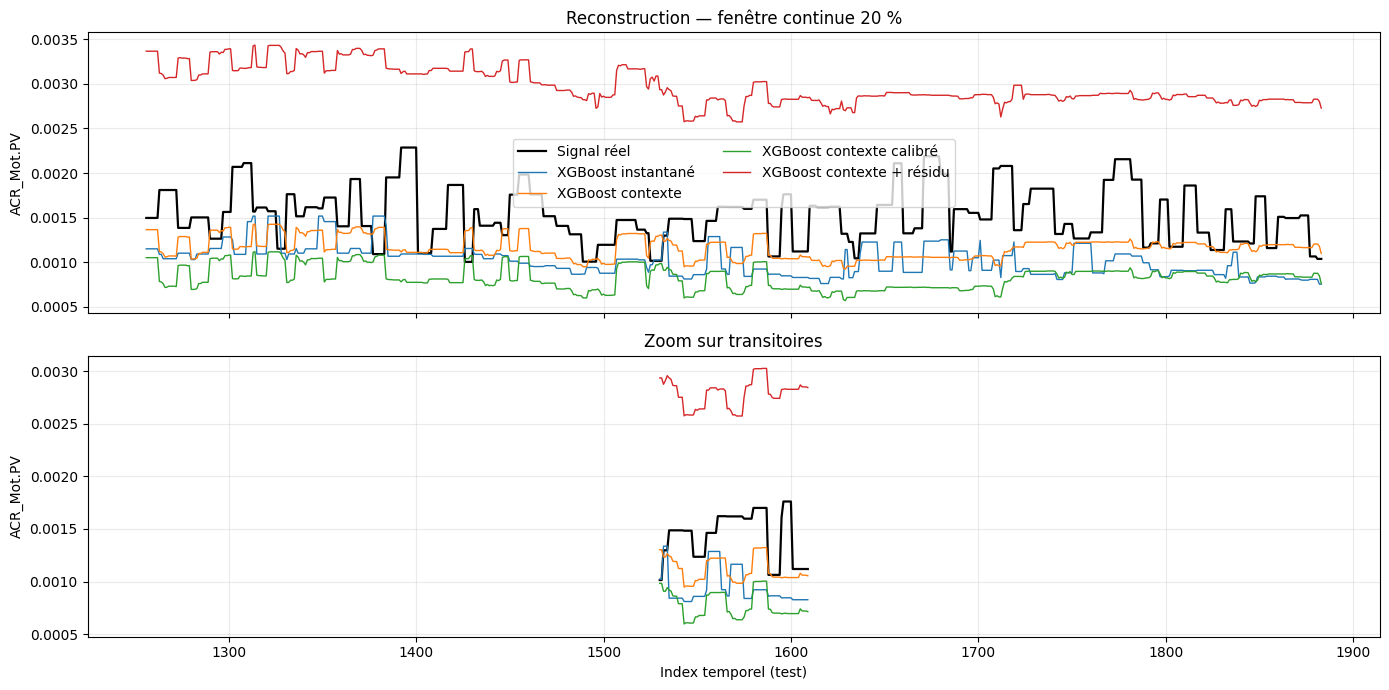

In [24]:
evaluation_rows = [evaluate_model(y_test_physical, prediction, mask, method, scenario) for scenario, mask in scenarios.items() for method, prediction in predictions.items()]
results_all_xgb = pd.DataFrame(evaluation_rows)
main_scenario = "Continuous 20%"; main_mask = scenarios[main_scenario]; idx = np.flatnonzero(main_mask)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(idx, y_test_physical[main_mask], color="black", lw=1.6, label="Signal réel")
for name, prediction in predictions.items(): axes[0].plot(idx, prediction[main_mask], lw=1.0, label=name)
axes[0].set(title="Reconstruction — fenêtre continue 20 %", ylabel=TARGET_SENSOR); axes[0].legend(ncol=2); axes[0].grid(alpha=.25)
zoom = slice(max(0, len(idx)//2-40), min(len(idx), len(idx)//2+40)); zoom_idx = idx[zoom]
axes[1].plot(zoom_idx, y_test_physical[zoom_idx], color="black", lw=1.6, label="Signal réel")
for name, prediction in predictions.items(): axes[1].plot(zoom_idx, prediction[zoom_idx], lw=1.0, label=name)
axes[1].set(title="Zoom sur transitoires", xlabel="Index temporel (test)", ylabel=TARGET_SENSOR); axes[1].grid(alpha=.25)
plt.tight_layout(); plt.show()


## Résultats

Sur le scénario principal (fenêtre continue de 20 % du Test, centrée) :

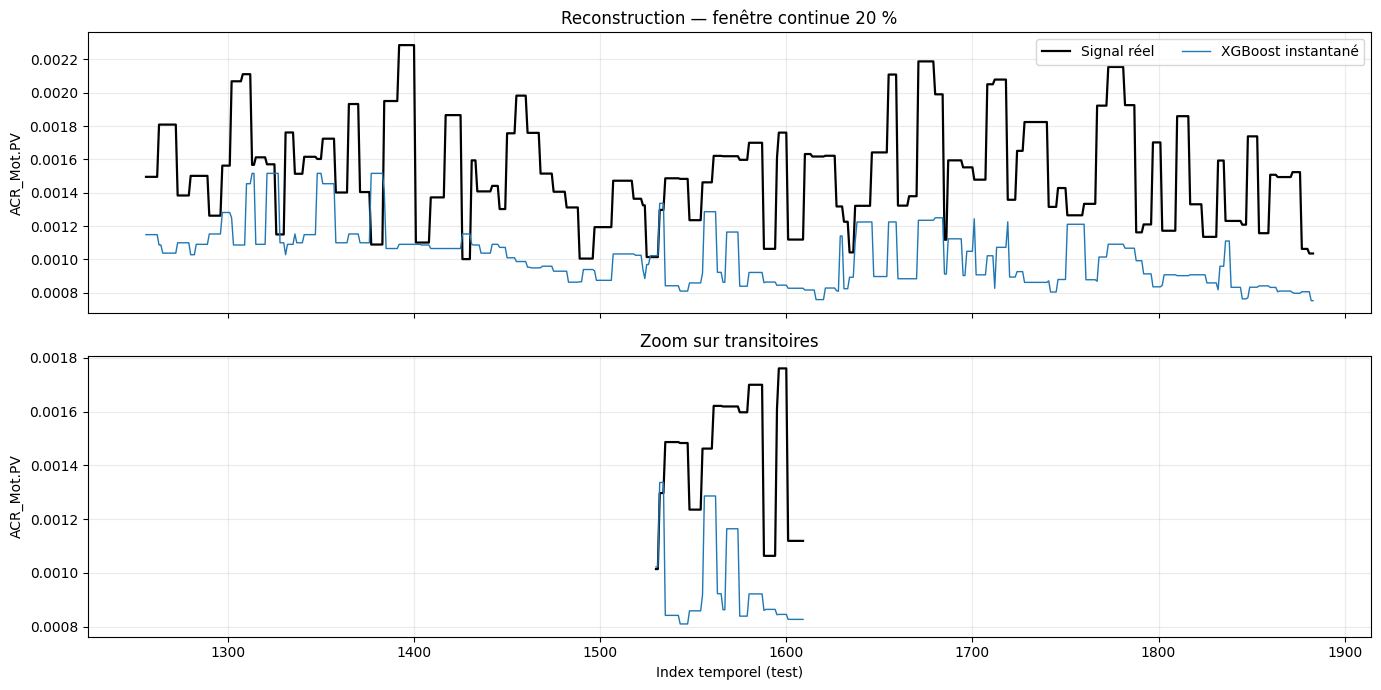

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [31]:
evaluation_rows = [evaluate_model(y_test_physical, prediction, mask, method, scenario) for scenario, mask in scenarios.items() for method, prediction in predictions.items()]
results_all_xgb = pd.DataFrame(evaluation_rows)
main_scenario = "Continuous 20%"; main_mask = scenarios[main_scenario]; idx = np.flatnonzero(main_mask)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(idx, y_test_physical[main_mask], color="black", lw=1.6, label="Signal réel")
cmp=0
for name, prediction in predictions.items(): 
  
    axes[0].plot(idx, prediction[main_mask], lw=1.0, label=name)
    axes[0].set(title="Reconstruction — fenêtre continue 20 %", ylabel=TARGET_SENSOR); axes[0].legend(ncol=2); axes[0].grid(alpha=.25)
    zoom = slice(max(0, len(idx)//2-40), min(len(idx), len(idx)//2+40)); zoom_idx = idx[zoom]
    axes[1].plot(zoom_idx, y_test_physical[zoom_idx], color="black", lw=1.6, label="Signal réel")
    axes[1].plot(zoom_idx, prediction[zoom_idx], lw=1.0, label=name)
    axes[1].set(title="Zoom sur transitoires", xlabel="Index temporel (test)", ylabel=TARGET_SENSOR); axes[1].grid(alpha=.25)
    plt.tight_layout(); plt.show()


   
    



| Méthode | RMSE | Normalized RMSE | R² | Corrélation | Ratio d'amplitude | Peak detection rate |
|---|---|---|---|---|---|---|
| **XGBoost contexte** (meilleur score composite) | 0,00050 | 1,60 | **-1,57** | **-0,025** | 0,395 | 0,304 |
| XGBoost instantané | 0,00060 | 1,94 | -2,77 | 0,207 | 0,595 | 0,217 |
| XGBoost calibration conditionnelle | 0,00081 | 2,60 | -5,74 | 0,011 | 0,886 | 0,304 |
| XGBoost contexte calibré | 0,00078 | 2,50 | -5,27 | -0,025 | 0,429 | 0,304 |
| XGBoost contexte + résidu | 0,00150 | 4,81 | -22,17 | 0,072 | 0,671 | 0,391 |
| XGBoost niveau-amplitude-forme | 0,00196 | 6,29 | -38,52 | 0,074 | 3,969 | 0,478 |

In [33]:
results_xgb = results_all_xgb.query("Scenario == @main_scenario").copy()
results_xgb["Selection_score"] = (SCORE_WEIGHTS["Normalized_RMSE"] * results_xgb["Normalized_RMSE"] + SCORE_WEIGHTS["Correlation"] * (1 - results_xgb["Correlation"]).abs() + SCORE_WEIGHTS["Std_ratio"] * (1 - results_xgb["Std_ratio"]).abs() + SCORE_WEIGHTS["Amplitude_ratio"] * (1 - results_xgb["Amplitude_ratio"]).abs())
results_xgb = results_xgb.sort_values(["Selection_score", "RMSE"]).reset_index(drop=True)
assert np.isfinite(results_xgb.select_dtypes(include=np.number).to_numpy()).all(), "Métriques non finies"
display(results_xgb[["Method","MAE","RMSE","Normalized_RMSE","R2","Correlation","Variance_ratio","Std_ratio","Amplitude_ratio","Peak_MAE","Peak_RMSE","Peak_detection_rate","Selection_score"]].round(5))
print("Résultats par scénario :"); display(results_all_xgb.sort_values(["Scenario", "RMSE"]).round(5))


,Method,MAE,RMSE,Normalized_RMSE,R2,Correlation,Variance_ratio,Std_ratio,Amplitude_ratio,Peak_MAE,Peak_RMSE,Peak_detection_rate,Selection_score
0,XGBoost contexte,0.00040,0.00050,1.60325,-1.57041,-0.02545,0.14846,0.38531,0.39537,0.00042,0.00072,0.30435,1.09025
1,XGBoost instantané,0.00052,0.00060,1.94055,-2.76572,0.20652,0.30394,0.55131,0.59483,0.00059,0.00084,0.21739,1.10569
2,XGBoost calibration conditionnelle,0.00070,0.00081,2.59536,-5.73590,0.01061,1.12170,1.05910,0.88592,0.00070,0.00055,0.30435,1.27066
3,XGBoost contexte calibré,0.00070,0.00078,2.50380,-5.26901,-0.02545,0.17506,0.41840,0.42934,0.00073,0.00103,0.30435,1.43706
4,XGBoost contexte + résidu,0.00145,0.00150,4.81343,-22.16914,0.07229,0.45100,0.67156,0.67131,0.00137,0.00118,0.39130,2.24234
5,XGBoost niveau–amplitude–forme,0.00128,0.00196,6.28662,-38.52164,0.07354,30.90318,5.55906,3.96856,0.00199,0.00169,0.47826,4.20547


Résultats par scénario :


,Method,Scenario,N_total,N_missing,MAE,RMSE,Normalized_RMSE,R2,Correlation,Variance_ratio,Std_ratio,Amplitude_ratio,Peak_MAE,Peak_RMSE,Peak_amplitude_error,Peak_detection_rate
7,XGBoost contexte,Continuous 10%,3140,314,0.00043,0.00051,1.73666,-2.01599,0.01738,0.15030,0.38768,0.39179,0.00034,0.00072,0.00034,0.36364
10,XGBoost calibration conditionnelle,Continuous 10%,3140,314,0.00049,0.00057,1.93329,-2.73762,-0.03371,0.67945,0.82429,0.92103,0.00065,0.00047,0.00065,0.36364
6,XGBoost instantané,Continuous 10%,3140,314,0.00053,0.00059,2.00352,-3.01409,0.31073,0.22325,0.47249,0.48668,0.00088,0.00082,0.00088,0.09091
8,XGBoost contexte calibré,Continuous 10%,3140,314,0.00075,0.00081,2.73022,-6.45412,0.01738,0.17723,0.42098,0.42545,0.00065,0.00103,0.00065,0.36364
11,XGBoost niveau–amplitude–forme,Continuous 10%,3140,314,0.00070,0.00122,4.12237,-15.99396,-0.05732,14.86387,3.85537,4.29544,0.00021,0.00145,0.00021,0.18182
9,XGBoost contexte + résidu,Continuous 10%,3140,314,0.00141,0.00145,4.88022,-22.81651,0.00716,0.32785,0.57258,0.69045,0.00154,0.00122,0.00154,0.36364
13,XGBoost contexte,Continuous 20%,3140,628,0.00040,0.00050,1.60325,-1.57041,-0.02545,0.14846,0.38531,0.39537,0.00042,0.00072,0.00042,0.30435
12,XGBoost instantané,Continuous 20%,3140,628,0.00052,0.00060,1.94055,-2.76572,0.20652,0.30394,0.55131,0.59483,0.00059,0.00084,0.00059,0.21739
14,XGBoost contexte calibré,Continuous 20%,3140,628,0.00070,0.00078,2.50380,-5.26901,-0.02545,0.17506,0.41840,0.42934,0.00073,0.00103,0.00073,0.30435
16,XGBoost calibration conditionnelle,Continuous 20%,3140,628,0.00070,0.00081,2.59536,-5.73590,0.01061,1.12170,1.05910,0.88592,0.00070,0.00055,0.00070,0.30435


In [34]:
winner = results_xgb.iloc[0]
print(f"Méthode première selon les résultats exécutés : {winner['Method']}")
print(f"RMSE={winner['RMSE']:.5f}; corrélation={winner['Correlation']:.4f}; std ratio={winner['Std_ratio']:.3f}; amplitude ratio={winner['Amplitude_ratio']:.3f}; peak RMSE={winner['Peak_RMSE']:.5f}")
print("La décision industrielle doit conserver les métriques individuelles : une forte corrélation ne compense pas un ratio de variance ou d'amplitude éloigné de 1.")


Méthode première selon les résultats exécutés : XGBoost contexte
RMSE=0.00050; corrélation=-0.0254; std ratio=0.385; amplitude ratio=0.395; peak RMSE=0.00072
La décision industrielle doit conserver les métriques individuelles : une forte corrélation ne compense pas un ratio de variance ou d'amplitude éloigné de 1.


**Le R² est négatif pour les six variantes, et la corrélation est proche de zéro voire négative
pour la moitié d'entre elles.** Même la variante retenue comme « meilleure » par le score composite
(XGBoost contexte, qui combine RMSE normalisée, corrélation, ratio d'écart-type et ratio
d'amplitude) a une corrélation de -0,025 avec le signal réel sur cette fenêtre -- c'est-à-dire
aucune relation exploitable. Le tableau complet par scénario (random 10 %, fenêtres continues
10/20/30 %, région de pics) confirme ce constat sur l'ensemble des scénarios testés, avec des R²
systématiquement négatifs, parfois au-delà de -20.

## Interprétation -- le résultat central de tout le corpus

Ce contraste doit être mis en regard direct des résultats du notebook 6 : **les mêmes familles de
modèles XGBoost passent d'un R² de 0,80 (notebook 6, évaluation instant par instant sur tout le
Test) à un R² de -38,5 (ce notebook, évaluation sur une fenêtre de panne continue réaliste).**
C'est, dans l'ensemble du corpus analysé, l'illustration la plus nette et la mieux chiffrée du
principe rappelé dans le cahier des charges de ce mémoire : **une métrique globale peut masquer un
échec localisé.** Un modèle évalué sur l'ensemble d'une période de test, qui mélange des zones
faciles (régime stable, information temporelle récente disponible) et des zones difficiles (panne
prolongée, transition de régime), peut sembler globalement performant tout en échouant
complètement sur le sous-ensemble industriellement critique.

Ce résultat dépasse le cadre de SINDy et de l'approche physique : **même un modèle d'apprentissage
supervisé purement statistique, sans prétention à l'interprétabilité physique, échoue sur le
scénario de panne continue.** L'hypothèse la plus probable, cohérente avec la construction même des
features contextuelles (retards, statistiques glissantes de l'historique récent), est que ces
modèles s'appuient fortement sur la continuité récente du signal cible pour bien prédire -- une
continuité qui, par construction, n'existe plus une fois la fenêtre de panne suffisamment longue,
puisque les retards du capteur cible lui-même deviennent obsolètes ou indisponibles au fil de la
fenêtre masquée. Cette lecture reste une hypothèse d'interprétation et non un résultat
expérimental démontré par les notebooks disponibles : elle mériterait une vérification dédiée
(par exemple en comparant explicitement les features qui utilisent l'historique du capteur cible
lui-même, si elles existent dans la chaîne, à celles qui n'utilisent que les autres capteurs).

Le ratio d'amplitude, très éloigné de 1 pour cinq des six variantes (0,395 à 0,886, ou au contraire
3,97 pour la variante niveau-amplitude-forme, largement sur-dispersée), confirme que le problème
n'est pas seulement une question de décalage temporel ou de bruit : c'est bien l'**échelle** du
signal reconstruit qui est fausse, exactement la distinction entre reconstruction de la dynamique
et reconstruction de l'amplitude posée dès le notebook 1.

## Limites

- Les six variantes de ce notebook n'ont pas été réévaluées avec le protocole du notebook 6
  (évaluation instant par instant sur tout le Test) : la comparaison directe entre les deux
  notebooks porte donc sur des familles de modèles proches mais pas rigoureusement identiques
  (features et hyperparamètres légèrement différents).
- L'explication proposée ci-dessus (dépendance à la continuité récente du signal cible) est une
  hypothèse d'interprétation, pas un résultat vérifié dans les notebooks disponibles.
- Le score composite utilisé pour désigner une variante « meilleure » (`Selection_score`) pondère
  RMSE normalisée, corrélation, ratio d'écart-type et ratio d'amplitude de façon arbitraire (poids
  fixés à 0,40/0,20/0,20/0,20) : un jeu de poids différent pourrait désigner une autre variante
  comme meilleure, sans changer le constat d'ensemble (R² négatif partout).

## Conclusion

Sur le scénario de panne continue -- le scénario industriellement pertinent -- **aucune des six
variantes XGBoost testées ne fournit une reconstruction utilisable.** Ce résultat, mis en regard du
notebook 6, montre qu'une évaluation instant par instant sur l'ensemble du Test peut donner une
impression de réussite entièrement démentie par une évaluation ciblée sur le cas critique.

## Transition vers l'approche suivante

Ce que ce notebook a établi : le problème de reconstruction de l'amplitude sur une fenêtre de
panne continue n'est pas spécifique à l'approche physique (SINDy, notebook 4-5) -- il touche
également l'apprentissage supervisé purement statistique (XGBoost). Ce qu'il laisse ouvert : quelle
part de cet échec vient de la dépendance des features à la continuité récente du signal cible,
quelle part vient de la difficulté intrinsèque du problème (information manquante des autres
capteurs), et si un CNN entraîné de bout en bout sur un scénario de panne explicitement simulé
pendant l'apprentissage (plutôt qu'ajouté après coup comme extracteur de features, comme au
notebook 6) se comporterait différemment -- une piste non testée dans le corpus disponible. La
question suivante n'est donc plus « quelle méthode choisir », mais : **que peut-on conclure, une
fois toutes les méthodes comparées sur un pied d'égalité, sur la difficulté structurelle de la
reconstruction d'amplitude ?** C'est l'objet du notebook 8.